# Backtesting signals without fooling ourselves

This notebook documents CryptoQuantLab's backtest engine: costed returns from a signal's positions, walk-forward selection, and the probabilistic and deflated Sharpe ratios that say how much a backtest's best result is worth after trying several variants. It then applies them to the moving-average crossovers the site's alerts already use, on every coin with a year of history. The Signals tab will be built on these; it is not on the site yet.

The models are [`signals.ts`](../../backend/src/models/signals.ts), [`backtest.ts`](../../backend/src/models/backtest.ts) and [`sharpeInference.ts`](../../backend/src/models/sharpeInference.ts). The reference is [`cql_validation/backtest.py`](../cql_validation/backtest.py); it is checked against pandas and against the numerical example in Bailey and López de Prado (2014), and the backend matches it to 1e-12 or better.

**The main result is that the crossovers show no timing skill.** The best of 15 crossovers looked significant on about 9% of coins by the usual test, and on 7% after deflating for the variants tried, but those were coins that rose anyway. Tested against the same coin's returns in shuffled order, only one coin in 70 beat chance at the 5% level, fewer than chance alone would give. Out of sample, the walk-forward crossover about matched holding the coin before costs while spending half its time out of the market, and fell slightly behind it after costs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent))
from cql_validation import backtest as bt

plt.rcParams.update({"figure.figsize": (9, 3.4), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

btc = pd.read_csv("../data/bitcoin_usd_daily.csv", parse_dates=["date"])
prices = btc["price_usd"].to_numpy()
dates = btc["date"]
annual = np.sqrt(365.25)
grid = [(s, l) for s in (1, 5, 10, 20) for l in (20, 30, 50, 100) if s < l]
start = 99
print(f"{len(prices)} Bitcoin daily closes, {dates.iloc[0]:%Y-%m-%d} to {dates.iloc[-1]:%Y-%m-%d}; {len(grid)} crossovers")

364 Bitcoin daily closes, 2025-10-23 to 2026-10-21; 15 crossovers


\
## 1. Costed returns

A signal produces a position $w_t \in [0, 1]$ from closes up to day $t$, held until the next close. Trades happen at \
the close and cost a fraction $c$ of the value traded, fee plus slippage, charged in the period the new position is \
first held:

$$r^{net}_{t+1} = w_t R_{t+1} - c\, |w_t - w_{t-1}|, \qquad w_{-1} = 0.$$

Using the close the signal was computed on is optimistic by however far the price moves while the order fills. A \
crossover is long while the short simple moving average is above the long one and flat otherwise; a short period of \
1 compares the price with its average. Shorts aren't modelled, since most holders can't short spot coins. The default \
cost is 15 basis points a trade, fee plus slippage. Many retail accounts pay more, so 30 is a check, with 0 for \
comparison.

The cell checks the reference against pandas computing the same thing a second way, and plots one crossover on \
Bitcoin.

largest gap to pandas: 0.0e+00
trades: 34, time in the market: 50%


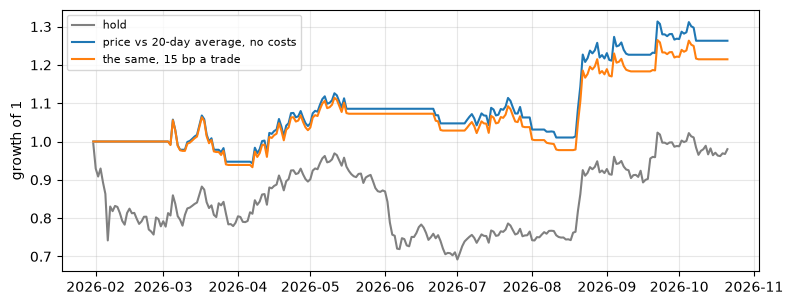

In [2]:
cost = 0.0015
positions = bt.crossover_positions(prices, 1, 20)
net = bt.strategy_returns(prices, positions, cost)
held = pd.Series(positions).shift(1).fillna(0)
library = (held * pd.Series(prices).pct_change() - cost * held.diff().abs().fillna(held)).to_numpy()[1:]
print(f"largest gap to pandas: {np.abs(net - library).max():.1e}")
print(f"trades: {int(np.abs(np.diff(positions)).sum())}, time in the market: {positions[start:].mean():.0%}")

days = dates.iloc[start + 1:]
fig, ax = plt.subplots()
ax.plot(days, np.cumprod(1 + (prices[1:] / prices[:-1] - 1)[start:]), label="hold", color="0.5")
ax.plot(days, np.cumprod(1 + bt.strategy_returns(prices, positions, 0)[start:]), label="price vs 20-day average, no costs")
ax.plot(days, np.cumprod(1 + net[start:]), label="the same, 15 bp a trade")
ax.set_ylabel("growth of 1")
ax.legend(fontsize=8)
plt.show()

\
## 2. How much is the best backtest worth?

The Sharpe ratio $\widehat{SR}$ of $T$ daily returns is an estimate with standard error of about $1/\sqrt{T}$: a \
daily Sharpe ratio of 0.05, 0.95 a year, from a year of data is within one standard error of zero. Two corrections \
make it usable as evidence.

**The probabilistic Sharpe ratio** (Bailey and López de Prado, 2012) is the probability that the true Sharpe ratio \
exceeds a benchmark $SR^*$, allowing for skewed, fat-tailed returns (Lo, 2002):

$$PSR(SR^*) = \Phi\left(\frac{(\widehat{SR} - SR^*)\sqrt{T - 1}}{\sqrt{1 - \hat\gamma_3 \widehat{SR} + \tfrac{\hat\gamma_4 - 1}{4}\widehat{SR}^2}}\right),$$

with $\hat\gamma_3$ the skewness and $\hat\gamma_4$ the kurtosis (3 for a normal distribution) of the returns, and \
Sharpe ratios per period, not annualized.

**The deflated Sharpe ratio** (Bailey and López de Prado, 2014) raises the benchmark to the Sharpe ratio expected from \
the best of $N$ independent trials with no skill,

$$SR_0 = \sqrt{V}\left((1 - \gamma)\,\Phi^{-1}\left(1 - \tfrac1N\right) + \gamma\, \Phi^{-1}\left(1 - \tfrac{1}{N e}\right)\right), \qquad DSR = PSR(SR_0),$$

where $V$ is the variance of the trials' Sharpe ratios and $\gamma$ is Euler's constant. Crossovers with nearby \
periods are nearly the same strategy, so 15 of them are not 15 independent trials. The paper's Appendix A.3 counts \
$M$ trials with average pairwise correlation $\bar\rho$ as $\hat N = \bar\rho + (1 - \bar\rho) M$ independent ones.

The paper's numerical example: 100 trials, annualized Sharpe ratio 2.5 and variance 1/2 across trials, 1,250 daily \
returns with skewness −3 and kurtosis 10. It reports $SR_0 = 0.1132$ and $DSR = 0.9004$, and 0.9505 had there been 46 \
trials.

In [3]:
def psr_from_moments(sr, benchmark, t, skew, kurt):
    return stats.norm.cdf((sr - benchmark) * np.sqrt(t - 1) / np.sqrt(1 - skew * sr + (kurt - 1) / 4 * sr**2))

sr, variance = 2.5 / np.sqrt(250), 0.5 / 250
pd.DataFrame({
    "published": [0.1132, 0.9004, 0.9505],
    "reference": [
        bt.expected_maximum_sharpe(100, variance),
        psr_from_moments(sr, bt.expected_maximum_sharpe(100, variance), 1250, -3, 10),
        psr_from_moments(sr, bt.expected_maximum_sharpe(46, variance), 1250, -3, 10),
    ],
}, index=["SR0, 100 trials", "DSR, 100 trials", "DSR, 46 trials"])

,published,reference
"SR0, 100 trials",0.1132,0.113172
"DSR, 100 trials",0.9004,0.900397
"DSR, 46 trials",0.9505,0.950502


Applied to the 15 crossovers on Bitcoin's 264 daily returns after the 100-day average exists:

In [4]:
evaluated = [bt.strategy_returns(prices, bt.crossover_positions(prices, s, l), cost)[start:] for s, l in grid]
sharpes = np.array([bt.sharpe(r) for r in evaluated])
best = int(np.argmax(sharpes))
implied = bt.implied_trials(np.array(evaluated))
pd.Series({
    "best crossover": "{}/{}".format(*grid[best]),
    "annualized Sharpe ratio": sharpes[best] * annual,
    "PSR against 0": bt.probabilistic_sharpe(evaluated[best], 0),
    "DSR, 15 trials": bt.deflated_sharpe(evaluated[best], sharpes),
    "implied independent trials": implied,
    "DSR, implied trials": bt.deflated_sharpe(evaluated[best], sharpes, implied),
}).to_frame("Bitcoin")

,Bitcoin
best crossover,1/20
annualized Sharpe ratio,1.07715
PSR against 0,0.830696
"DSR, 15 trials",0.528769
implied independent trials,5.14031
"DSR, implied trials",0.637834


On Bitcoin the price-versus-20-day crossover ended well ahead of holding, as the chart above shows, but after deflating for the variants tried, a probability of about 0.64 that its Sharpe ratio is really above zero is weak evidence.

### Are the tests calibrated?

A test that passes at 0.95 should pass about 5% of the time when nothing is there. The next cell checks this with pure noise: $N$ independent strategies of 278 fat-tailed daily returns, as many as each coin has below, (Student-t, 4 degrees of freedom) with a true Sharpe ratio of zero, keeping the best.

In [5]:
rng = np.random.default_rng(1)
rows = {}
for n in (1, 5, 15, 50):
    psr, dsr = [], []
    for _ in range(2000):
        x = rng.standard_t(4, (n, 278)) * 0.03
        s = np.array([bt.sharpe(r) for r in x])
        b = int(np.argmax(s))
        psr.append(bt.probabilistic_sharpe(x[b], 0))
        dsr.append(bt.deflated_sharpe(x[b], s))
    rows[n] = {"PSR > 0.95": np.mean(np.array(psr) > 0.95), "DSR > 0.95": np.mean(np.array(dsr) > 0.95)}
pd.DataFrame(rows).T.rename_axis("independent trials").map(lambda v: f"{v:.2%}")

,PSR > 0.95,DSR > 0.95
independent trials,,
1,5.70%,5.70%
5,26.20%,0.15%
15,57.65%,0.15%
50,93.35%,0.15%


With one trial both pass about 5% of the time, a little more because of the fat tails. **Keeping the best of 15 undeflated passes more than half the time.** The deflated Sharpe ratio fixes that and overshoots: it passes almost never, because $SR_0$ is the *expected* best of $N$, not a high percentile of it, so beating it by 1.645 standard errors is far rarer than 5%. DSR is a conservative test rather than an exact one.

Crossovers are not independent trials. [`scripts/crossover_backtest.py`](../scripts/crossover_backtest.py) ran the 15-crossover search 20 times on each coin's own returns in shuffled order with the mean removed, at 15 bp, so there was nothing to earn:

In [6]:
null = pd.read_csv("../data/crossover_backtest_null.csv")
coins = pd.read_csv("../data/crossover_backtest_coins.csv")
print(f"{len(null)} searches on {null.coin.nunique()} coins; median implied trials {null.implied_trials.median():.1f}")
pd.Series({
    "PSR > 0.95": np.mean(null.psr > 0.95),
    "DSR > 0.95, 15 trials": np.mean(null.dsr > 0.95),
    "DSR > 0.95, implied trials": np.mean(null.dsr_implied > 0.95),
}).map(lambda v: f"{v:.1%}").to_frame("passed on shuffled prices")

1400 searches on 70 coins; median implied trials 4.3


,passed on shuffled prices
PSR > 0.95,11.5%
"DSR > 0.95, 15 trials",1.1%
"DSR > 0.95, implied trials",2.6%


The undeflated test passes the best crossover two to three times as often as it should. Deflating for all 15 overcorrects, and the implied number of trials, about 4, lands closer to 5% while staying conservative.

## 3. Crossovers on 70 coins

Every coin with 378 days of history and daily volatility of at least 0.5%, which leaves out stablecoins, from October 2025 to November 2026. Each is tested on the 278 daily returns after the 100-day average exists.

In [7]:
costs = ["0bp", "15bp", "30bp"]
pd.DataFrame({
    tag: {
        "PSR > 0.95": np.mean(coins[f"psr_{tag}"] > 0.95),
        "DSR > 0.95, 15 trials": np.mean(coins[f"dsr_{tag}"] > 0.95),
        "DSR > 0.95, implied trials": np.mean(coins[f"dsr_implied_{tag}"] > 0.95),
        "median best Sharpe, annualized": coins[f"in_sample_sharpe_{tag}"].median(),
    }
    for tag in costs
}).map(lambda v: f"{v:.2f}" if v > 0.3 else f"{v:.1%}")

,0bp,15bp,30bp
PSR > 0.95,10.0%,8.6%,8.6%
"DSR > 0.95, 15 trials",5.7%,5.7%,5.7%
"DSR > 0.95, implied trials",8.6%,7.1%,7.1%
"median best Sharpe, annualized",0.74,0.73,0.67


Five coins pass the deflated test at 15 bp, a little more than the 2.6% false-positive rate above would give by chance (about two coins). But DSR asks whether the Sharpe ratio is above zero, not whether the timing helped. A long-or-flat strategy on a coin that rose steadily has a positive Sharpe ratio without timing anything.

The direct test of timing keeps each coin's trend and shuffles only the order of its returns, 200 times, rerunning the whole 15-crossover search each time. The p-value is the share of shuffles whose best Sharpe ratio is at least the real one: a permutation test in the spirit of White's (2000) reality check.

           coin  best  crossover Sharpe  holding Sharpe  DSR, implied  timing p-value
gatechain-token  5/20           2.18661        0.202988      0.967062      0.00995025
           just 5/100           2.89366         2.89795      0.984492        0.457711
           near  5/20           2.37862         1.76795      0.975291       0.0746269
   venice-token 10/20           2.55971         2.52454      0.985113        0.547264
          zcash 10/30           2.79515         1.87127      0.992657        0.104478

timing p-value below 0.05: 1 of 70 coins; below 0.10: 5


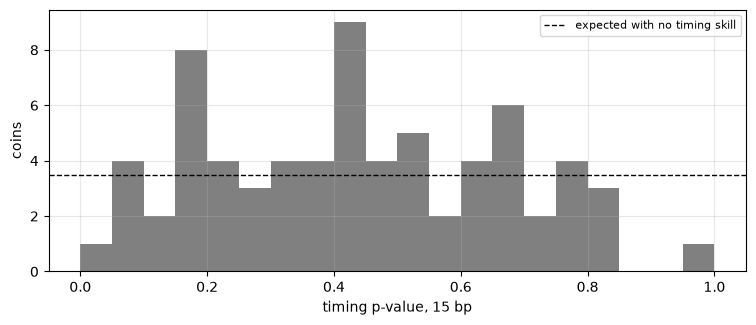

In [8]:
passed = coins[coins.dsr_implied_15bp > 0.95]
print(passed[["coin", "best_15bp", "in_sample_sharpe_15bp", "hold_in_sample_sharpe", "dsr_implied_15bp", "timing_p_value"]]
      .rename(columns={"best_15bp": "best", "in_sample_sharpe_15bp": "crossover Sharpe", "hold_in_sample_sharpe": "holding Sharpe",
                       "dsr_implied_15bp": "DSR, implied", "timing_p_value": "timing p-value"}).to_string(index=False))
print()
print(f"timing p-value below 0.05: {(coins.timing_p_value < 0.05).sum()} of {len(coins)} coins; below 0.10: {(coins.timing_p_value < 0.10).sum()}")

fig, ax = plt.subplots()
ax.hist(coins.timing_p_value, bins=np.linspace(0, 1, 21), color="0.5")
ax.axhline(len(coins) / 20, color="k", lw=1, ls="--", label="expected with no timing skill")
ax.set_xlabel("timing p-value, 15 bp")
ax.set_ylabel("coins")
ax.legend(fontsize=8)
plt.show()

For JUST and Venice the best crossover's Sharpe ratio is the same as holding the coin: they pass because the coins rose. Only GateChain's timing p-value is below 0.05, one coin where chance alone would give three or four. Five p-values fall below 0.1 and one above 0.9, where an even spread would put about seven in each. The coins move together, so the 70 tests aren't independent, and the shuffle also removes volatility clustering, so the shape says little; what matters is that there is no cluster of small p-values.

## 4. Walk-forward

Choosing the best crossover over the whole year and reporting its Sharpe ratio uses the same data twice. Walk-forward selection trains on 120 days, holds the best crossover for the next 30, and moves on, so every reported day is out of sample, and switching between crossovers pays its trading cost. The comparison is holding the coin over the same 158 test days, paying the same cost to buy in.

In [9]:
pd.DataFrame({
    tag: {
        "median best Sharpe, in sample": coins[f"in_sample_sharpe_{tag}"].median(),
        "median walk-forward Sharpe": coins[f"walk_forward_sharpe_{tag}"].median(),
        "median holding Sharpe": coins.hold_sharpe.median(),
        "walk-forward beats holding": np.mean(coins[f"walk_forward_sharpe_{tag}"] > coins.hold_sharpe),
        "median time in the market": coins[f"walk_forward_exposure_{tag}"].median(),
        "median crossover switches": coins[f"walk_forward_switches_{tag}"].median(),
    }
    for tag in costs
})

,0bp,15bp,30bp
"median best Sharpe, in sample",0.743576,0.725842,0.672192
median walk-forward Sharpe,0.371265,0.319341,0.26123
median holding Sharpe,0.354092,0.354092,0.354092
walk-forward beats holding,0.571429,0.528571,0.471429
median time in the market,0.474684,0.474684,0.487342
median crossover switches,3,3,3


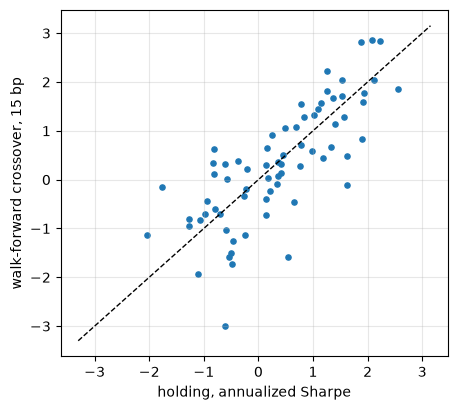

In [10]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(coins.hold_sharpe, coins.walk_forward_sharpe_15bp, s=14)
lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, color="k", lw=1, ls="--")
ax.set_xlabel("holding, annualized Sharpe")
ax.set_ylabel("walk-forward crossover, 15 bp")
plt.show()

The best in-sample Sharpe ratio roughly halves out of sample, as selection bias predicts, even though holding did better on the test days than over the whole year. The walk-forward crossover beat holding on 57% of coins with no costs, 53% at 15 bp and 47% at 30 bp, while spending about half its time out of the market. On these days that is a similar Sharpe ratio with less exposure, not an edge. The training windows overlap the in-sample year, so only the out-of-sample columns are a fair comparison.

## 5. What this means for the Signals tab

- **Show the deflated Sharpe ratio with the implied number of trials,** and the number of variants tried next to it. The undeflated PSR passes the best of 15 crossovers on pure noise two or three times as often as it should.
- **Compare with holding the coin.** A positive Sharpe ratio on a coin that rose is not a signal. Each backtest table should show holding over the same days, and the timing p-value is the better test of whether the signal adds anything. It needs a few hundred reruns per coin, so it belongs in the nightly job, not the API.
- **Lead with walk-forward results,** with costs, rather than the best in-sample backtest.
- **Present crossovers as descriptions of trend, not predictions.** Over this year they showed no timing skill.

## 6. Limitations

- **One year.** 278 daily returns per coin once the 100-day average exists, and 158 out-of-sample days. A 200-day crossover, the classic golden cross, would leave 178 and isn't tested.
- **Survivorship.** The coins come from today's top 100.
- **The coins move together,** so 70 coins are far fewer than 70 independent tests.
- **Shuffling removes volatility clustering** as well as any timing information, so the timing p-value tests both.
- **Costs are a flat rate** at the daily close; spreads widen exactly when crossovers tend to fire.

## References

- Bailey, D. H., Borwein, J. M., López de Prado, M. and Zhu, Q. J. (2014). Pseudo-mathematics and financial charlatanism: the effects of backtest overfitting on out-of-sample performance. *Notices of the American Mathematical Society*, 61(5), 458–471.
- Bailey, D. H. and López de Prado, M. (2012). The Sharpe ratio efficient frontier. *Journal of Risk*, 15(2), 3–44.
- Bailey, D. H. and López de Prado, M. (2014). The deflated Sharpe ratio: correcting for selection bias, backtest overfitting and non-normality. *Journal of Portfolio Management*, 40(5), 94–107.
- Brock, W., Lakonishok, J. and LeBaron, B. (1992). Simple technical trading rules and the stochastic properties of stock returns. *Journal of Finance*, 47(5), 1731–1764.
- Lo, A. W. (2002). The statistics of Sharpe ratios. *Financial Analysts Journal*, 58(4), 36–52.
- White, H. (2000). A reality check for data snooping. *Econometrica*, 68(5), 1097–1126.